In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("house_prices.csv")

In [4]:
df.head()

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  object 
 2   Description        184508 non-null  object 
 3   Amount(in rupees)  187531 non-null  object 
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  object 
 6   Carpet Area        106858 non-null  object 
 7   Status             186916 non-null  object 
 8   Floor              180454 non-null  object 
 9   Transaction        187448 non-null  object 
 10  Furnishing         184634 non-null  object 
 11  facing             117298 non-null  object 
 12  overlooking        106095 non-null  object 
 13  Society            77853 non-null   object 
 14  Bathroom           186703 non-null  object 
 15  Balcony            138596 non-null  object 
 16  Ca

In [6]:
df.size

3938151

In [7]:
df.isnull().sum()

Index                     0
Title                     0
Description            3023
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
Dimensions           187531
Plot Area            187531
dtype: int64

In [8]:
df['BHK'] = df['Title'].str.split().str[0]

df['BHK'] = pd.to_numeric(df['BHK'], errors='coerce')

In [9]:
df.head(5)

,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,...,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area,BHK
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,...,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN,1.0
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,...,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN,2.0
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,...,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN,2.0
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,...,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN,1.0
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,...,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN,2.0


In [10]:
# Drop unnecessary columns
drop_cols = [
    'Index',
    'Description',
    'Dimensions',
    'Plot Area',
    'Title',
    
]

df.drop(columns=drop_cols, inplace=True)

# Check remaining columns
print(df.columns)

# Check missing values
print(df.isnull().sum())

Index(['Amount(in rupees)', 'Price (in rupees)', 'location', 'Carpet Area',
       'Status', 'Floor', 'Transaction', 'Furnishing', 'facing', 'overlooking',
       'Society', 'Bathroom', 'Balcony', 'Car Parking', 'Ownership',
       'Super Area', 'BHK'],
      dtype='object')
Amount(in rupees)         0
Price (in rupees)     17665
location                  0
Carpet Area           80673
Status                  615
Floor                  7077
Transaction              83
Furnishing             2897
facing                70233
overlooking           81436
Society              109678
Bathroom                828
Balcony               48935
Car Parking          103357
Ownership             65517
Super Area           107685
BHK                     953
dtype: int64


In [11]:
df.head()

,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,1.0
1,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,2.0
2,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,2.0
3,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,2.0


In [12]:
df.count()

Amount(in rupees)    187531
Price (in rupees)    169866
location             187531
Carpet Area          106858
Status               186916
Floor                180454
Transaction          187448
Furnishing           184634
facing               117298
overlooking          106095
Society               77853
Bathroom             186703
Balcony              138596
Car Parking           84174
Ownership            122014
Super Area            79846
BHK                  186578
dtype: int64

In [13]:
df.drop(['Price (in rupees)', 'Society'], axis=1, inplace=True)

In [14]:
df.head(5)

,Amount(in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42 Lac,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98 Lac,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,1 Open,Freehold,NaN,2.0
2,1.40 Cr,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,1 Covered,Freehold,NaN,2.0
3,25 Lac,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,1.60 Cr,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,1 Covered,Co-operative Society,NaN,2.0


In [15]:
df.rename(
    columns={'Amount(in rupees)': 'Price_in_Lakhs'},
    inplace=True
)

In [16]:
df.head()

,Price_in_Lakhs,location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42 Lac,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98 Lac,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,1 Open,Freehold,NaN,2.0
2,1.40 Cr,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,1 Covered,Freehold,NaN,2.0
3,25 Lac,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,1.60 Cr,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,1 Covered,Co-operative Society,NaN,2.0


In [17]:
def convert_to_lakh(x):
    if pd.isna(x):
        return None

    x = str(x).strip().lower()

    if 'cr' in x:
        return float(x.replace('cr', '').strip()) * 100

    elif 'lac' in x:
        return float(x.replace('lac', '').strip())

    return pd.to_numeric(x, errors='coerce')


df['Price_in_Lakhs']=df['Price_in_Lakhs'].apply(convert_to_lakh)

In [18]:
df.head()

,Price_in_Lakhs,location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,1 Open,Freehold,NaN,2.0
2,140.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,1 Covered,Freehold,NaN,2.0
3,25.0,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,160.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,1 Covered,Co-operative Society,NaN,2.0


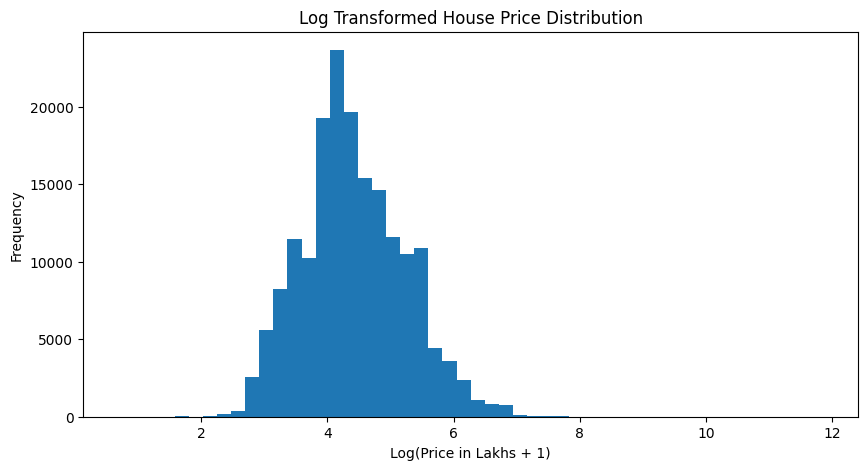

In [19]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(np.log1p(df['Price_in_Lakhs']), bins=50)

plt.xlabel('Log(Price in Lakhs + 1)')
plt.ylabel('Frequency')
plt.title('Log Transformed House Price Distribution')

plt.show()

In [20]:
df.nunique()

Price_in_Lakhs    1559
location            81
Carpet Area       2758
Status               1
Floor              947
Transaction          4
Furnishing           3
facing               8
overlooking         19
Bathroom            11
Balcony             11
Car Parking        229
Ownership            4
Super Area        2976
BHK                 10
dtype: int64

In [21]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: Price_in_Lakhs
Price_in_Lakhs
NaN       9684
85.0      5264
65.0      4229
60.0      3869
70.0      3801
          ... 
988.0        1
1775.0       1
374.0        1
19.7         1
990.0        1
Name: count, Length: 1560, dtype: int64

Column: location
location
new-delhi      27599
bangalore      24030
kolkata        22380
gurgaon        20070
ahmedabad      12750
               ...  
nellore           30
solapur           30
madurai           30
palakkad          30
pondicherry       30
Name: count, Length: 81, dtype: int64

Column: Carpet Area
Carpet Area
NaN          80673
1000 sqft     5285
900 sqft      4649
1300 sqft     3457
1600 sqft     2752
             ...  
1867 sqft        1
2415 sqft        1
1712 sqft        1
2404 sqft        1
136 sqft         1
Name: count, Length: 2759, dtype: int64

Column: Status
Status
Ready to Move    186916
NaN                 615
Name: count, dtype: int64

Column: Floor
Floor
2 out of 4      12433
1 out of 4      11985
3 out of 4      

In [22]:
df.dropna(subset=['Price_in_Lakhs'], inplace=True)

In [23]:
df.shape

(177847, 15)

In [24]:
df.head()

,Price_in_Lakhs,location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,1 Open,Freehold,NaN,2.0
2,140.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,1 Covered,Freehold,NaN,2.0
3,25.0,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,160.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,1 Covered,Co-operative Society,NaN,2.0


In [25]:
print(df['location'].value_counts(dropna=False))

location
new-delhi      24945
bangalore      23262
kolkata        21605
gurgaon        18846
ahmedabad      12614
               ...  
solapur           30
ahmadnagar        30
nellore           29
pondicherry       29
madurai           26
Name: count, Length: 81, dtype: int64


In [26]:
location_counts = df['location'].value_counts()

df['location'] = df['location'].apply(
    lambda x: 'Other' if location_counts[x] < 1000 else x
)

In [27]:
print(df['location'].value_counts())
print("Unique locations:", df['location'].nunique())

location
new-delhi        24945
bangalore        23262
kolkata          21605
gurgaon          18846
Other            17157
ahmedabad        12614
hyderabad        11147
chennai          10163
jaipur            7867
greater-noida     4490
faridabad         3733
vadodara          2361
surat             2180
pune              2177
thane             1869
mumbai            1814
visakhapatnam     1729
mohali            1479
zirakpur          1478
chandigarh        1402
noida             1247
goa               1153
ranchi            1065
bhiwadi           1035
kochi             1029
Name: count, dtype: int64
Unique locations: 25


In [28]:
df['Carpet Area'] = pd.to_numeric(
    df['Carpet Area'].astype(str).str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

In [29]:
df.rename(
    columns={'Carpet Area': 'Carpet_Area_sqft'},
    inplace=True
)

In [30]:
df.head(5)

,Price_in_Lakhs,location,Carpet_Area_sqft,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42.0,thane,500.0,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98.0,thane,473.0,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,NaN,1 Open,Freehold,NaN,2.0
2,140.0,thane,779.0,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,NaN,1 Covered,Freehold,NaN,2.0
3,25.0,thane,530.0,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,160.0,thane,635.0,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,NaN,1 Covered,Co-operative Society,NaN,2.0


In [31]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: Price_in_Lakhs
Price_in_Lakhs
85.0      5264
65.0      4229
60.0      3869
70.0      3801
35.0      3369
          ... 
988.0        1
1775.0       1
374.0        1
19.7         1
990.0        1
Name: count, Length: 1559, dtype: int64

Column: location
location
new-delhi        24945
bangalore        23262
kolkata          21605
gurgaon          18846
Other            17157
ahmedabad        12614
hyderabad        11147
chennai          10163
jaipur            7867
greater-noida     4490
faridabad         3733
vadodara          2361
surat             2180
pune              2177
thane             1869
mumbai            1814
visakhapatnam     1729
mohali            1479
zirakpur          1478
chandigarh        1402
noida             1247
goa               1153
ranchi            1065
bhiwadi           1035
kochi             1029
Name: count, dtype: int64

Column: Carpet_Area_sqft
Carpet_Area_sqft
NaN         76325
1000.0       5226
900.0        4617
1300.0       3446
1600.0       

In [32]:
df['Balcony']=df['Balcony'].fillna(0)

In [33]:
df.head()

,Price_in_Lakhs,location,Carpet_Area_sqft,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Car Parking,Ownership,Super Area,BHK
0,42.0,thane,500.0,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,NaN,1.0
1,98.0,thane,473.0,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,0,1 Open,Freehold,NaN,2.0
2,140.0,thane,779.0,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,0,1 Covered,Freehold,NaN,2.0
3,25.0,thane,530.0,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,NaN,1.0
4,160.0,thane,635.0,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,0,1 Covered,Co-operative Society,NaN,2.0


In [34]:
df.drop(columns=['Car Parking'],inplace=True)

In [35]:
df.head()

,Price_in_Lakhs,location,Carpet_Area_sqft,Status,Floor,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,Super Area,BHK
0,42.0,thane,500.0,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,1,2,NaN,NaN,1.0
1,98.0,thane,473.0,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,2,0,Freehold,NaN,2.0
2,140.0,thane,779.0,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,2,0,Freehold,NaN,2.0
3,25.0,thane,530.0,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,1,1,NaN,NaN,1.0
4,160.0,thane,635.0,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",2,0,Co-operative Society,NaN,2.0


In [36]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: Price_in_Lakhs
Price_in_Lakhs
85.0      5264
65.0      4229
60.0      3869
70.0      3801
35.0      3369
          ... 
988.0        1
1775.0       1
374.0        1
19.7         1
990.0        1
Name: count, Length: 1559, dtype: int64

Column: location
location
new-delhi        24945
bangalore        23262
kolkata          21605
gurgaon          18846
Other            17157
ahmedabad        12614
hyderabad        11147
chennai          10163
jaipur            7867
greater-noida     4490
faridabad         3733
vadodara          2361
surat             2180
pune              2177
thane             1869
mumbai            1814
visakhapatnam     1729
mohali            1479
zirakpur          1478
chandigarh        1402
noida             1247
goa               1153
ranchi            1065
bhiwadi           1035
kochi             1029
Name: count, dtype: int64

Column: Carpet_Area_sqft
Carpet_Area_sqft
NaN         76325
1000.0       5226
900.0        4617
1300.0       3446
1600.0       

In [37]:
df.drop(
    columns=['Status', 'Super Area'],
    inplace=True
)

In [38]:
df['Floor_Number'] = pd.to_numeric(
    df['Floor'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

df['Total_Floors'] = pd.to_numeric(
    df['Floor'].str.extract(r'out of\s*(\d+)')[0],
    errors='coerce'
)

df.drop(columns=['Floor'], inplace=True)

In [39]:
df.head()

,Price_in_Lakhs,location,Carpet_Area_sqft,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,BHK,Floor_Number,Total_Floors
0,42.0,thane,500.0,Resale,Unfurnished,NaN,NaN,1,2,NaN,1.0,10.0,11.0
1,98.0,thane,473.0,Resale,Semi-Furnished,East,Garden/Park,2,0,Freehold,2.0,3.0,22.0
2,140.0,thane,779.0,Resale,Unfurnished,East,Garden/Park,2,0,Freehold,2.0,10.0,29.0
3,25.0,thane,530.0,Resale,Unfurnished,NaN,NaN,1,1,NaN,1.0,1.0,3.0
4,160.0,thane,635.0,Resale,Unfurnished,West,"Garden/Park, Main Road",2,0,Co-operative Society,2.0,20.0,42.0


In [40]:
categorical_cols = [
    'Transaction',
    'Furnishing',
    'facing',
    'overlooking',
    'Ownership'
]

for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

In [41]:
numerical_cols = [
    'Carpet_Area_sqft',
    'Bathroom',
    'Balcony',
    'BHK',
    'Floor_Number',
    'Total_Floors'
]

print(df[numerical_cols].dtypes)

Carpet_Area_sqft    float64
Bathroom             object
Balcony              object
BHK                 float64
Floor_Number        float64
Total_Floors        float64
dtype: object


In [42]:
print(df['Bathroom'].unique())
print(df['Balcony'].unique())

['1' '2' '3' '4' '6' nan '5' '9' '8' '> 10' '7' '10']
['2' 0 '1' '3' '4' '6' '5' '7' '> 10' '10' '8' '9']


In [43]:
cols = ['Bathroom', 'Balcony']

for col in cols:
    df[col] = df[col].replace('> 10', '11')
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [44]:
print(df['Bathroom'].unique())
print(df['Balcony'].unique())

[ 1.  2.  3.  4.  6. nan  5.  9.  8. 11.  7. 10.]
[ 2  0  1  3  4  6  5  7 11 10  8  9]


In [45]:
df['Bathroom'] = df['Bathroom'].fillna(0)

In [46]:
print(df['Bathroom'].isnull().sum())
print(df['Bathroom'].value_counts())

0
Bathroom
2.0     88999
3.0     54187
1.0     15509
4.0     14826
5.0      3281
0.0       760
6.0       187
7.0        32
11.0       29
8.0        14
10.0       12
9.0        11
Name: count, dtype: int64


In [47]:
df.head()

,Price_in_Lakhs,location,Carpet_Area_sqft,Transaction,Furnishing,facing,overlooking,Bathroom,Balcony,Ownership,BHK,Floor_Number,Total_Floors
0,42.0,thane,500.0,Resale,Unfurnished,Unknown,Unknown,1.0,2,Unknown,1.0,10.0,11.0
1,98.0,thane,473.0,Resale,Semi-Furnished,East,Garden/Park,2.0,0,Freehold,2.0,3.0,22.0
2,140.0,thane,779.0,Resale,Unfurnished,East,Garden/Park,2.0,0,Freehold,2.0,10.0,29.0
3,25.0,thane,530.0,Resale,Unfurnished,Unknown,Unknown,1.0,1,Unknown,1.0,1.0,3.0
4,160.0,thane,635.0,Resale,Unfurnished,West,"Garden/Park, Main Road",2.0,0,Co-operative Society,2.0,20.0,42.0


In [48]:
df.describe()

,Price_in_Lakhs,Carpet_Area_sqft,Bathroom,Balcony,BHK,Floor_Number,Total_Floors
count,177847.000000,101522.000000,177847.000000,177847.000000,177500.000000,170893.000000,170852.000000
mean,119.813442,1226.384912,2.439023,1.479356,2.590135,4.841954,8.798510
std,394.382694,3119.368046,0.872036,1.209181,0.775751,4.645418,7.558992
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,48.400000,770.250000,2.000000,0.000000,2.000000,2.000000,4.000000
50%,78.000000,1050.000000,2.000000,1.000000,3.000000,3.000000,5.000000
75%,145.000000,1500.000000,3.000000,2.000000,3.000000,6.000000,11.000000
max,140030.000000,709222.000000,11.000000,11.000000,10.000000,200.000000,200.000000


In [49]:
df.corr(numeric_only=True)

,Price_in_Lakhs,Carpet_Area_sqft,Bathroom,Balcony,BHK,Floor_Number,Total_Floors
Price_in_Lakhs,1.000000,0.047554,0.214877,0.105151,0.186486,0.096044,0.108298
Carpet_Area_sqft,0.047554,1.000000,0.171757,0.086517,0.164947,0.056732,0.061093
Bathroom,0.214877,0.171757,1.000000,0.351013,0.810386,0.242909,0.275018
Balcony,0.105151,0.086517,0.351013,1.000000,0.376763,0.192324,0.219609
BHK,0.186486,0.164947,0.810386,0.376763,1.000000,0.204913,0.199223
Floor_Number,0.096044,0.056732,0.242909,0.192324,0.204913,1.000000,0.733036
Total_Floors,0.108298,0.061093,0.275018,0.219609,0.199223,0.733036,1.000000


In [50]:
print(df[categorical_cols].isnull().sum())

Transaction    0
Furnishing     0
facing         0
overlooking    0
Ownership      0
dtype: int64


In [51]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


Transaction:
Transaction
Resale          135630
New Property     41445
Other              703
Unknown             67
Rent/Lease           2
Name: count, dtype: int64

Furnishing:
Furnishing
Semi-Furnished    82868
Unfurnished       73491
Furnished         19421
Unknown            2067
Name: count, dtype: int64

facing:
facing
Unknown         65736
East            52244
North - East    23349
North           15302
West             8474
South            4316
North - West     3803
South - East     2571
South -West      2052
Name: count, dtype: int64

overlooking:
overlooking
Unknown                           75825
Main Road                         29683
Garden/Park, Main Road            26351
Garden/Park                       22833
Garden/Park, Pool, Main Road      12285
Pool, Garden/Park, Main Road       3402
Garden/Park, Pool                  2842
Main Road, Garden/Park, Pool       1353
Pool, Main Road                    1131
Pool                                999
Main Road, Garden/Par

In [52]:
df['Transaction'] = df['Transaction'].replace(
    'Rent/Lease', 'Other'
)

In [53]:
df.drop(columns=['overlooking'], inplace=True)

In [54]:
print(df.columns)
print(df.shape)

Index(['Price_in_Lakhs', 'location', 'Carpet_Area_sqft', 'Transaction',
       'Furnishing', 'facing', 'Bathroom', 'Balcony', 'Ownership', 'BHK',
       'Floor_Number', 'Total_Floors'],
      dtype='object')
(177847, 12)


In [55]:
categorical_cols = [
    'location',
    'Transaction',
    'Furnishing',
    'facing',
    'Ownership'
]

In [56]:
df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [57]:
df.head()

,Price_in_Lakhs,Carpet_Area_sqft,Bathroom,Balcony,BHK,Floor_Number,Total_Floors,location_ahmedabad,location_bangalore,location_bhiwadi,...,facing_North - West,facing_South,facing_South - East,facing_South -West,facing_Unknown,facing_West,Ownership_Freehold,Ownership_Leasehold,Ownership_Power Of Attorney,Ownership_Unknown
0,42.0,500.0,1.0,2,1.0,10.0,11.0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
1,98.0,473.0,2.0,0,2.0,3.0,22.0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,140.0,779.0,2.0,0,2.0,10.0,29.0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,25.0,530.0,1.0,1,1.0,1.0,3.0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
4,160.0,635.0,2.0,0,2.0,20.0,42.0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [58]:
# Separate input and target
X = df.drop(columns=['Price_in_Lakhs'])
y = df['Price_in_Lakhs']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (177847, 48)
Target shape: (177847,)


In [59]:
numerical_cols = [
    'Carpet_Area_sqft',
    'Bathroom',
    'Balcony',
    'BHK',
    'Floor_Number',
    'Total_Floors'
]

In [60]:
print(X[numerical_cols].dtypes)


Carpet_Area_sqft    float64
Bathroom            float64
Balcony               int64
BHK                 float64
Floor_Number        float64
Total_Floors        float64
dtype: object


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [62]:
# Create copies of training and testing data
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

# Numerical columns to handle
outlier_cols = [
    'Carpet_Area_sqft',
    'Floor_Number',
    'Total_Floors',
    'Bathroom',
    'Balcony'
]

# Store IQR limits
iqr_limits = {}

for col in outlier_cols:

    Q1 = X_train_xgb[col].quantile(0.25)
    Q3 = X_train_xgb[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    iqr_limits[col] = (lower_limit, upper_limit)

    # Cap training values
    X_train_xgb[col] = X_train_xgb[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

    # Apply training limits to testing data
    X_test_xgb[col] = X_test_xgb[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("IQR outlier capping completed!")

IQR outlier capping completed!


In [63]:
print("Training shape:", X_train_xgb.shape)
print("Testing shape:", X_test_xgb.shape)

print("Data types:")
print(X_train_xgb.dtypes.value_counts())

Training shape: (142277, 48)
Testing shape: (35570, 48)
Data types:
int64      43
float64     5
Name: count, dtype: int64


In [64]:
from sklearn.preprocessing import StandardScaler

In [65]:
scaler = StandardScaler()

# Fit only on training data
X_train_xgb[numerical_cols] = scaler.fit_transform(
    X_train_xgb[numerical_cols]
)

# Transform test data using the same scaler
X_test_xgb[numerical_cols] = scaler.transform(
    X_test_xgb[numerical_cols]
)

In [66]:
y_train_log = np.log1p(y_train)

In [67]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_xgb, y_train_log)

print("XGBoost training completed!")

XGBoost training completed!


In [68]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

In [69]:
def evaluate_model(y_test, y_pred, model_name):

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    print(f"\n{model_name} Evaluation")
    print("-" * 40)
    print(f"MAE  : {mae:.4f} Lakhs")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f} Lakhs")
    print(f"R2   : {r2:.4f}")
    print(f"MAPE : {mape:.2f}%")

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2,
        "MAPE (%)": mape
    }

In [70]:
# Predict
y_pred_log = xgb_model.predict(X_test_xgb)

# Convert back to actual prices
y_pred_xgb = np.expm1(y_pred_log)

# Evaluate
xgb_results = evaluate_model(
    y_test,
    y_pred_xgb,
    "Improved XGBoost"
)


Improved XGBoost Evaluation
----------------------------------------
MAE  : 20.7768 Lakhs
MSE  : 568571.9149
RMSE : 754.0371 Lakhs
R2   : 0.0263
MAPE : 15.49%


In [71]:
importance = pd.DataFrame({
    'Feature': X_train_xgb.columns,
    'Importance': xgb_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(20))

                   Feature  Importance
1                 Bathroom    0.216030
21      location_new-delhi    0.079390
3                      BHK    0.069598
20         location_mumbai    0.061802
7       location_bangalore    0.058146
27       location_vadodara    0.054467
16         location_jaipur    0.046259
8         location_bhiwadi    0.042486
29       location_zirakpur    0.029469
15      location_hyderabad    0.026974
14        location_gurgaon    0.026141
13  location_greater-noida    0.024378
18        location_kolkata    0.022487
0         Carpet_Area_sqft    0.020856
11      location_faridabad    0.019460
5             Total_Floors    0.018251
12            location_goa    0.013805
47       Ownership_Unknown    0.012282
2                  Balcony    0.011663
26          location_thane    0.011655


In [72]:
# Training predictions
y_train_pred_log = xgb_model.predict(X_train_xgb)

# Convert back to actual prices
y_train_pred = np.expm1(y_train_pred_log)

# Evaluate training performance
train_results = evaluate_model(
    y_train,
    y_train_pred,
    "XGBoost Training Performance"
)

# Testing performance
test_results = evaluate_model(
    y_test,
    y_pred_xgb,
    "XGBoost Testing Performance"
)


XGBoost Training Performance Evaluation
----------------------------------------
MAE  : 16.2055 Lakhs
MSE  : 33104.4426
RMSE : 181.9463 Lakhs
R2   : 0.3165
MAPE : 15.42%

XGBoost Testing Performance Evaluation
----------------------------------------
MAE  : 20.7768 Lakhs
MSE  : 568571.9149
RMSE : 754.0371 Lakhs
R2   : 0.0263
MAPE : 15.49%


In [73]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Scale features
scaler = StandardScaler()

X_train_ann = scaler.fit_transform(X_train)
X_test_ann = scaler.transform(X_test)

# Transform target
y_train_ann = np.log1p(y_train)
y_test_ann = np.log1p(y_test)

In [74]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization,
    Input
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(42)

ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.25),

    Dense(64, activation='relu'),
    Dropout(0.2),

    Dense(1)
])

ann_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │          12,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,297 (216.00 KB)

 Trainable params: 54,529 (213.00 KB)

 Non-trainable params: 768 (3.00 KB)

In [75]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

history = ann_model.fit(
    X_train_ann,
    y_train_ann,
    validation_split=0.15,
    epochs=150,
    batch_size=256,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - loss: 2.3974 - mae: 1.1022 - val_loss: 0.6587 - val_mae: 0.6406 - learning_rate: 0.0010
Epoch 2/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.8533 - mae: 0.7355 - val_loss: 0.6570 - val_mae: 0.6404 - learning_rate: 0.0010
Epoch 3/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.8343 - mae: 0.7283 - val_loss: 0.6821 - val_mae: 0.6463 - learning_rate: 0.0010
Epoch 4/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - loss: 0.8281 - mae: 0.7255 - val_loss: 0.6657 - val_mae: 0.6575 - learning_rate: 0.0010
Epoch 5/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.8197 - mae: 0.7219 - val_loss: 0.6545 - val_mae: 0.6448 - learning_rate: 0.0010
Epoch 6/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - loss: 0.8080 - mae: 0.7168 - val_loss: 0.6580 - val_mae: 0.6495 - learning_rate: 0.0010
Epoch 7/150
473/473 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - loss: 0.7966 - mae: 0.7115 - val_loss: 0.6533 - val_mae: 0.6421 - learning_

In [76]:
y_pred_log = ann_model.predict(X_test_ann).flatten()

# Convert predictions back to Lakhs
y_pred_ann = np.expm1(y_pred_log)

1112/1112 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step


In [77]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred_ann)

mse = mean_squared_error(y_test, y_pred_ann)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_ann)

mape = np.mean(
    np.abs((y_test - y_pred_ann) / np.maximum(y_test, 1e-8))
) * 100

print("ANN Testing Performance")
print("-----------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)
print("MAPE:", mape)

ANN Testing Performance
-----------------------
MAE : 76.85488580866212
MSE : 585621.3715334994
RMSE: 765.259022510352
R2  : -0.0028916381327368512
MAPE: 77.65565437119656
